# 08 Phase 8: figures, tables and summary

**What this shows.** Every figure and table below is regenerated by `scripts/make_all_figures_tables.py` from the frozen bundle and saved artifacts, with no test-set access. The soft flags and the honest headline findings come first, as in `artifacts/SUMMARY.md`.

In [1]:
import sys, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 60); pd.set_option('display.max_rows', 200)
r = subprocess.run([sys.executable, 'scripts/make_all_figures_tables.py'], cwd=ROOT, capture_output=True, text=True)
print('regeneration exit code:', r.returncode); print(r.stdout[-600:])
display(Markdown((ROOT / 'artifacts' / 'SUMMARY.md').read_text(encoding='utf-8')))

regeneration exit code: 0
figures: ['fairness_groups.png', 'leakage_before_after.png', 'pareto_deployable_test.png', 'reliability_by_gender.png', 'taiwan_pareto.png', 'tradeoff_sweep_validation.png']
tables: ['diag_meta.json', 'diag_paired_diffs.csv', 'diag_validation_table.csv', 'guard_audit.json', 'jta_summary.csv', 'leakage_after.csv', 'matched_pair.csv', 'paired_diffs_test.csv', 'shap_proxy.json', 'taiwan_results.csv', 'taiwan_test.md', 'test_results_all_arms.csv', 'test_results_all_arms.md', 'three_way_diffs.csv', 'three_way_table.csv', 'val_vs_test.csv']



# SUMMARY: Fairness-aware credit scoring (empirical study)

> **SOFT FLAGS (read first)**
> 1. The joint model (JT chosen, 0.05/2/0) does **not** beat the sequential baseline (class weights + analytic prior correction + gender-blind fairness step, S1 / S2-EG) on fairness, calibration or AUC. Its validation EOD (0.0234) was optimistic: 0.0363 on test.
> 2. Single-step GRL failed in the Phase 4 single-step runs (validation numbers, control probe 0.785): probe 0.67 to 0.81, adversary loss up to 8 to 16, AUC-ROC 0.46 to 0.73. Multi-step GRL test probes are 0.759 to 0.773 (A2 0.791); gender stays recoverable. JT chosen's test probe of 0.801 has the adversary off and is not a GRL result.
> 3. FLAG_OWN_CAR enters the JT top-15 SHAP features and has single-feature gender AUC >= 0.60: possible new proxy.
> 4. Matched-pair gaps are not reduced by JT (mean |delta| 0.0336 vs A2 0.0297).
> 5. JT chosen worst-group ECE is 0.0198 on test (cap 0.02), 0.0238 on 5 validation seeds: at the limit.
> 6. Mixed SHAP sample sizes (17 arms 4,000 test rows, ten arms 5,000).
> 7. Taiwan: JT chosen loses 0.05 AUC-PR with unchanged lambdas (no re-tuning by rule); EOD differences there are mostly within noise.
> 8. Predictions in Phase 6 were scored with bf16 on GPU; the served fp32 model differs by 0.00184 on the test pool (in the manifest).
> 9. A different tool (Codex) edited the working tree without authorisation during Phase 6; edits were reviewed, tested and kept (RUN_LOG, overnight section A). Two harness memory kills occurred and were resolved by reducing the workload.
> 10. The Phase 7 browser check ran on Edge only, on port 8765 (port 8000 was held by the owner's separate VECTOR API (`run_vector.py api`, PID 47112), not by a leftover server of this project as first written). A human visual review is still pending.
> 11. ThresholdOptimizer is not flag-rate matched (flags 34.7% of applicants): analysis only.

Scope. An **empirical study** of how imbalance correction, a fairness intervention and calibration interact in credit scoring, plus a joint objective `L = weighted_CE + lambda_f*fairness + lambda_c*calibration + lambda_a*adversarial` that makes the trade-off explicit. It is not a new method. Data: Home Credit Default Risk (Kaggle, **not Indian data**); secondary check: UCI Default of Credit Card Clients (Taiwan).

## 1. Main test results (Home Credit, held-out test set, mean of 3 seeds, shared rule: flag the top 10% by the validation 90th-percentile threshold)

Full table with 95% paired-bootstrap CIs: `artifacts/tables/test_results_all_arms.md` / `.csv`. Deployable = gender-blind at inference. Analysis only = uses gender at inference (reference, not a deployment option).

| Arm | Use | AUC-ROC | AUC-PR | Worst-group ECE | EOD | DIR |
|---|---|---|---|---|---|---|
| A0 plain TabTransformer | deployable | .7439 | .2189 | .0151 | .0668 | .946 |
| A2 class weights | deployable | .7463 | .2209 | .3496 | .0601 | .951 |
| S1 A2 + prior correction | deployable | .7463 | .2209 | .0131 | .0601 | .951 |
| **S2-EG** S1 + ExponentiatedGradient (v2) | deployable | .7463 | .2209 | .0131 | **.0151** | .989 |
| G1 | deployable | .7445 | .2209 | .1925 | .0239 | .970 |
| **JT chosen (0.05, 2, 0)** (served) | deployable | .7433 | .2145 | .0198 | .0363 | .982 |
| JT tuned | deployable | .7424 | .2124 | .0260 | .0221 | .989 |
| JT-A k5 la0.25 (multi-step GRL) | deployable | .7429 | .2150 | .0249 | .0212 | .987 |
| H1 / H3 (hybrids) | deployable | .7414 / .7161 | .2109 / .1715 | .0258 / .0642 | .0274 / .0330 | .993 / .997 |
| **REF LightGBM** | deployable | .7661 | .2513 | .0085 | .0849 | .942 |
| per-group Platt | analysis only | .7473 | .2223 | .0055 | .1221 | .919 |
| S2-GT group thresholds | analysis only | .7463 | .2209 | .0131 | .0213 | .992 |
| ThresholdOptimizer (not rate-matched) | analysis only | .7463 | .2209 | .0131 | .0294 | .994 |

Paired test differences, JT chosen minus S2-EG: AUC-ROC -0.0029, AUC-PR -0.0065, worst-group ECE +0.0056 (all significant), EOD +0.0177 (CI 0.0008 to 0.0310, significant). JT chosen is significantly behind S2-EG on AUC-ROC, AUC-PR, worst-group ECE, EOD and DIR (DIR -0.0075), and tied on recall (+0.0058, CI includes 0); the EOD gap is barely significant. JT's EOD gain over A2 and S1 is not significant on test (-0.0238, CI -0.0602 to 0.0109). Tuned JT ties S2-EG on EOD (+0.0050, CI includes 0) and DIR. The rule-selected JT has the adversary off (lambda_a = 0); JT-A with all three terms on (k5, lambda_a 0.25) has better EOD (0.0212) and lower leakage (about 0.76 vs 0.80) but exceeds the 0.02 worst-group ECE cap (0.0249). S2-EG's AUC and ECE come from the S1 score while its flags come from the EG mixture; the EG score's own validation AUC-PR is 0.2198 vs 0.2212, so the conclusion does not change.

## 2. Headline findings (honest)

1. **Gender is recoverable from the features** (AUC about 0.90), so removing the gender column does not remove gender information.
2. **Weighted loss breaks calibration; the prior-correction formula repairs it.** A2 worst-group ECE .3496; S1 .0131 at identical ranking (AUC-PR .2209).
3. **The sequential pipeline matched or beat the joint model** at lower complexity (S2-EG EOD .0151 vs JT .0363, with better AUC and calibration).
4. **Single-step GRL fails to remove gender from z** (Phase 4 single-step runs (validation numbers, control probe 0.785): probe 0.67 to 0.81, adversary loss up to 8 to 16, AUC-ROC 0.46 to 0.73); **multi-step GRL lowers the fresh-probe AUC modestly** (test: 0.759 to 0.773, A2 0.791). Gender is still recoverable. JT chosen (0.801 on test) has the adversary off, not a GRL result.
5. **LightGBM is ahead of the TabTransformer** by about 0.019 AUC-ROC and 0.030 AUC-PR (REF vs A2), with the worst fairness gap among the deployable arms except A1/A1b.
6. **Matched-pair check:** the nearest other-gender applicant differs by 0.030 (A2) to 0.034 (JT) on average; only H3 clearly shrinks it (0.0036), at AUC-PR .1715.
7. **Validation-selected fairness regresses on test** (JT 0.0234 to 0.0363; H1 0.0069 to 0.0274). AUC-PR and ECE transferred well.
8. **UCI Taiwan** (70/15/15, same hyper-parameters, no re-tuning): gender from features AUC about 0.65; S1 repairs calibration (worst-group ECE .030 vs A2 .226); JT chosen AUC-PR .488 vs A2 .537; the fairness gap is small from the start (A0 EOD .029), so EOD differences are mostly noise. The direction of the Home Credit pattern holds.

## 3. Configurations tried (for disclosure)

Optuna trials: 10 per tuned arm (A0, A1, A1b, A2, A3, A4, A5, G1 = 80) plus 10 for tuned JT = 90; the first Phase 2 run (kept) tuned the same arms once more with different trials. JT lambda points: 20 main + 6 confusion-adversary + 8 fine = 34 compared by the rule (+2 ablation-only points). Smoke/diagnostic joint configurations: 9. Phase 4 adversary rescue: 10 variants plus a control. Multi-step GRL rescue: 32 variants (57 runs including extra seeds). H arms: 3. S2-EG: 2 implementations (v1 unmatched, kept; v2 final) plus 6 eps values. REF: 4 LightGBM settings. S2 group thresholds: 1 grid search. The selection rule was applied twice (26 and 34 points) with the same winner. After the test run, a three-way lambda exploration added 20 more lambda points (60 runs: 12 class-weighted, 8 unweighted; validation only, selection rule not re-applied; section 9), plus the validation-only JT-A+PH diagnostic (section 8). Home Credit test set: 28 guard-log entries (1 whitelisted probe + exactly 1 per arm for 27 arms); Taiwan: 8 entries.

## 4. Claims checklist (docs/CRITICAL_RULES.md rules 19 to 22)

| Rule | Status |
|---|---|
| 19 No "novel method", "first", "no prior work", "solves fairness"; "to our knowledge" only after a literature search | Met in this document; no literature search has been done, so the phrase is not used. Re-check the paper text. |
| 20 Never imply validation on Indian borrowers | Met: Home Credit and Taiwan are stated as non-Indian on every page and here. |
| 21 Report negative results honestly | Met: JT not dominating the sequential baseline, LightGBM ahead, GRL leakage failure, optimistic validation fairness are all reported above. |
| 22 Cite Kleinberg et al. 2016 AND Pleiss et al. 2017 precisely; do not say Kleinberg proves an equalized-odds vs calibration conflict | Not applicable to this summary; apply in the paper text (docs/PROJECT_CONTEXT.md has the wording). |

## 5. Threats to validity

One dataset family (plus one small secondary dataset); one protected attribute (gender, binary in the data); non-Indian data; Home Credit application table only (no bureau or previous-application tables); lambdas selected on validation (test regressions seen); probe results carry seed noise (z-probe sd 0.005 to 0.019); a single hyper-parameter tuning draw per arm (10 trials); mixed SHAP sample counts (4,000 vs 5,000); bf16 scoring in Phase 6 vs fp32 serving (gap 0.00184); EOD is noisy with CIs about 0.03 wide; the flag-rate rule is one choice of operating point.

## 6. Serving demo (Phase 7)

Served model: JT chosen, seed 0, fp32 CPU, no post-hoc correction; risk bands low < 0.0807 (train default rate) < medium < 0.194 (validation 90th percentile) < high. The dashboard states: "On this dataset the sequential baseline (class weights + prior correction + gender-blind fairness step) matched or beat the joint model." Every page carries the research-prototype disclaimer. `/predict` p95 16.9 ms; `/explain` 486 ms.

## 7. Reproduction

```
.venv\Scripts\activate
pytest                                   # 150 tests
python scripts/freeze_bundle.py          # rebuild artifacts/bundle/v1 from saved artifacts (no test access)
uvicorn api.main:app --port 8000         # demo at http://127.0.0.1:8000/
python scripts/make_all_figures_tables.py   # all figures and tables from the bundle and saved artifacts
```

Test predictions live in `artifacts/test_preds/` (Home Credit) and `artifacts/test_preds_taiwan/`; all analysis reads these files only. Run folders: `artifacts/runs/` (Phase 6: `artifacts/phase6_rundir.txt`). Narrative and gates: `artifacts/RUN_LOG.md`. Notebooks: `notebooks/01` to `08`.

## 8. Diagnostics (validation only; declared after the test run; NOT in the test table)

Folder `artifacts/runs/20261102_diagE/` (tables copied to `artifacts/tables/diag_*.csv`). 3 seeds, 500 paired bootstrap resamples.
- **JT-W (importance-weighted ECE term): not run, hypothesis rejected.** The stratified sampler reproduces the population (batch default rate 0.0806 vs 0.0807; gender share 0.3418 vs 0.3416; min-per-cell floor 64 never binds), so importance weights equal 1.0 and JT-W would equal JT chosen. A sampler mismatch is therefore not the reason the joint model underperforms.
- **JT-A+PH** (spec GRL, 5 adversary steps, lambda_a 0.25, lambda_f 0.05, lambda_c 0, then S1 prior correction, then S2-EG v2), validation means:

| Arm | AUC-ROC | AUC-PR | Worst-group ECE | EOD | DIR |
|---|---|---|---|---|---|
| JT chosen | .7428 | .2146 | .0189 | .0234 | .975 |
| S2-EG | .7460 | .2212 | .0123 | .0108 | .984 |
| JT-A+PH raw | .7399 | .2100 | .3263 | .0182 | .982 |
| JT-A+PH + S1 | .7399 | .2100 | .0290 | .0182 | .982 |
| JT-A+PH + S1 + S2-EG | .7399 | .2100 | .0290 | .0071 | .986 |

Paired differences (95% CI): JT-A+PH + S1 + S2-EG minus S2-EG: AUC-ROC -0.0061 (sig.), AUC-PR -0.0112 (sig.), worst-group ECE +0.0159 (sig.), EOD -0.0012 (CI -0.0131 to 0.0109, not distinguishable). Versus JT chosen: AUC-PR -0.0045 (sig.), worst-group ECE +0.0108 (sig.), EOD -0.0113 (CI -0.0224 to 0.0007, not significant). Verdict: adding the multi-step adversary before the post-hoc steps costs ranking quality and calibration and gives no fairness gain that is distinguishable from S2-EG; the sequential baseline still stands. Validation numbers only; no test access was made (guard logs unchanged).

## 9. Three-way lambda exploration (validation only; diagnostic, declared after the test run; NOT in the test table)

Pre-declared in commit `58453d5`, at the owner's request, because the lambdas interact and the main sweep held lambda_a at 0. 20 points x 3 seeds = 60 runs, adv_steps 5. Tables: `artifacts/tables/three_way_table.csv`, `three_way_diffs.csv`. The selection rule was not re-applied or edited; the limits below are only used as a yardstick. Differences are not corrected for multiple comparisons, and validation fairness has been optimistic before (JT chosen EOD 0.0234 to 0.0363 on test).

**No point passes all the rule's limits, and none beats S2-EG on AUC-PR (best .2154 vs .2212).**

| Point (lambda_f, lambda_c, lambda_a) | AUC-ROC | AUC-PR | Worst-group ECE | EOD | DIR | z-probe |
|---|---|---|---|---|---|---|
| Reference: JT chosen (0.05, 2, 0) | .7428 | .2146 | .0189 | .0234 | .975 | about .80 |
| Reference: S2-EG | .7460 | .2212 | .0123 | .0108 | .984 | n/a |
| Weighted (0.05, 2, 0.25), closest to all limits | .7425 | .2127 | .0203 | .0126 | .980 | .757 |
| Weighted (0.05, 1, 0.1), best AUC-PR | .7413 | .2154 | .0626 | .0128 | .985 | .749 |
| Weighted (0.05, 0.5, 0.1), lowest EOD | .7428 | .2153 | .1392 | .0056 | .986 | .754 |
| Weighted (0.1, 0.5, 0.25), lowest weighted z-probe | .7384 | .2101 | .1457 | .0077 | .986 | .722 |
| Unweighted (0.05, 0, 0), best unweighted AUC-PR | .7315 | .2016 | .0299 | .0160 | .986 | .714 |
| Unweighted (0.05, 0, 0.25), lowest z-probe | .7278 | .2011 | .0364 | .0146 | .988 | .681 |
| Unweighted (0.1, 0.5, 0) | .6647 | .1375 | .0186 | .0470 | .980 | .823 |

Paired differences for weighted (0.05, 2, 0.25): against JT chosen, EOD -0.0090 (CI -0.0197 to 0.0017, not significant), DIR +0.0052 (sig.), worst-group ECE +0.0014 (sig.), AUC-PR -0.0018 (not significant). Against S2-EG, AUC-ROC -0.0036, AUC-PR -0.0085, worst-group ECE +0.0066, DIR -0.0040 (all sig.), EOD +0.0010 (not significant).

Findings:
1. The lambdas do interact. Lowering lambda_c from 2 to 0.5 raises worst-group ECE from about .02 to about .14 and changes EOD and the z-probe. Keeping all three on gives a modest gain over JT chosen (lower leakage, better DIR, EOD lower but not significantly) at about the same AUC.
2. Calibration remains the limit: in the weighted grid only lambda_c = 2 gets near the cap, and the one point there at .0203 misses it narrowly. Low-lambda_c points are reported raw, without prior correction.
3. The hypothesis that class weights and the calibration term were fighting is NOT supported. Unweighted joint models are worse (AUC-PR at most .2016, vs A0's .2201 alone), and adding lambda_c = 0.5 collapses them (AUC-ROC about .67).
4. Three-way tuning does not change the headline: the sequential baseline stays ahead on ranking and calibration. These are hypotheses for future work on fresh data, not test results. The served model and test table are unchanged.


## Figures

pareto_deployable_test


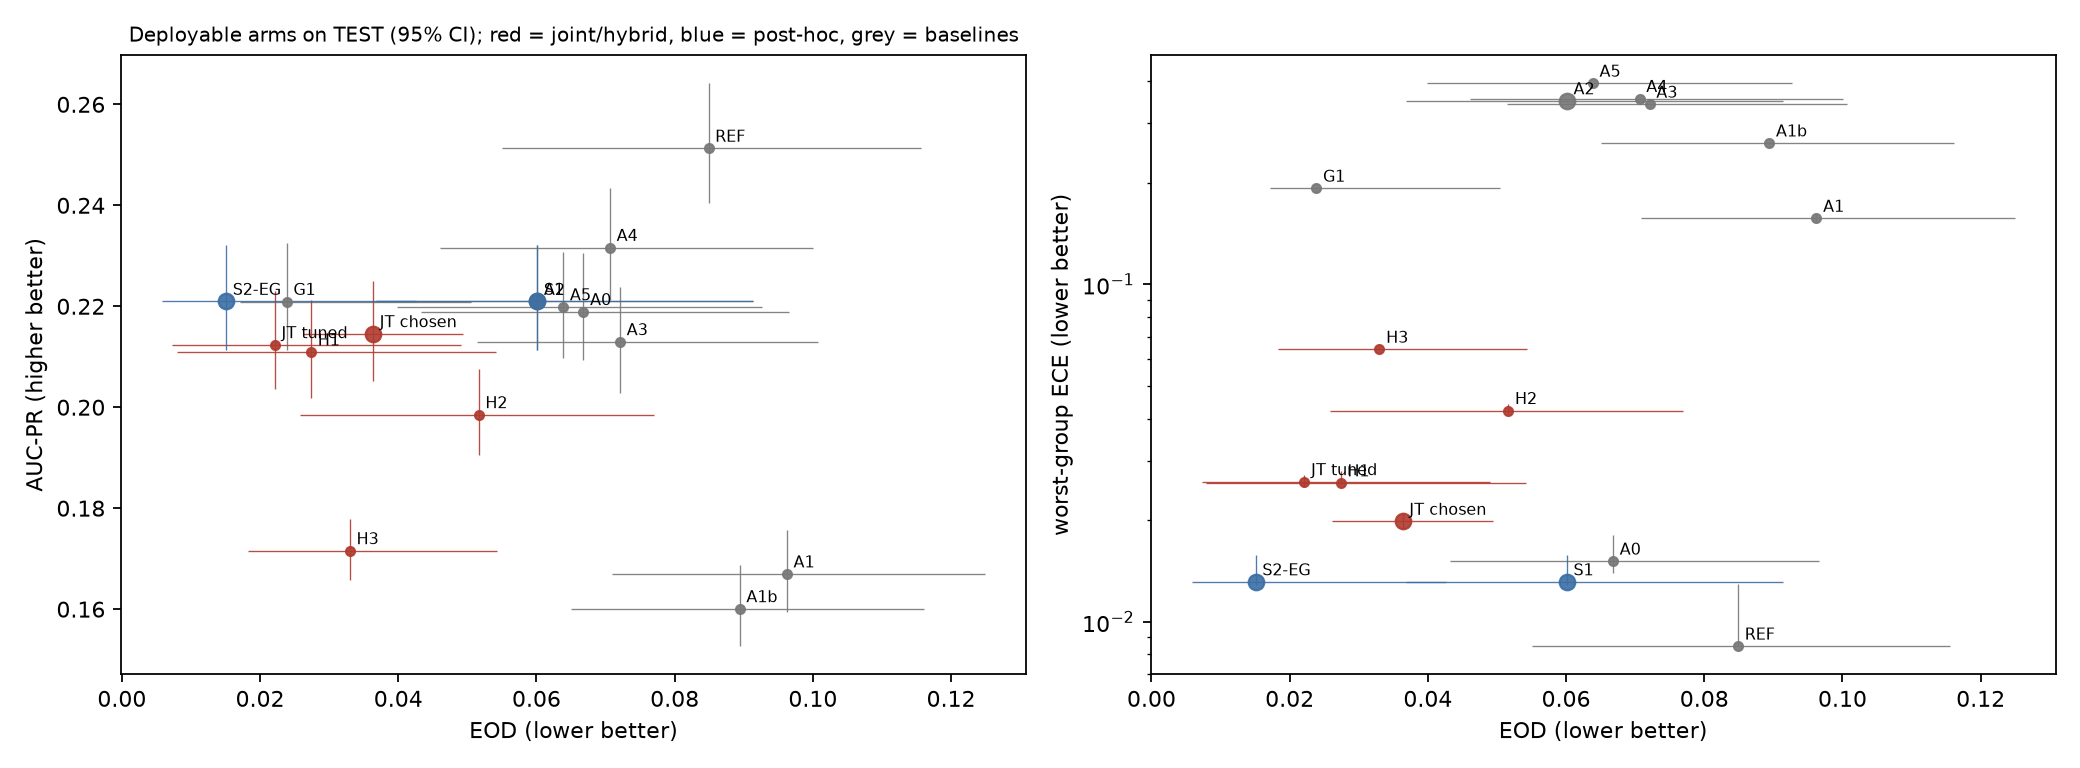

reliability_by_gender


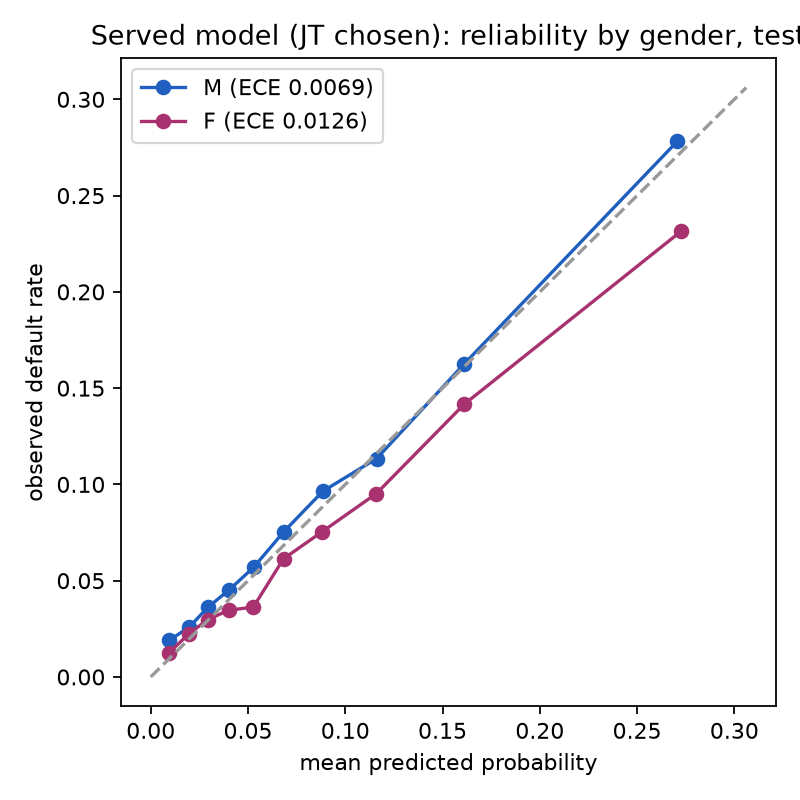

leakage_before_after


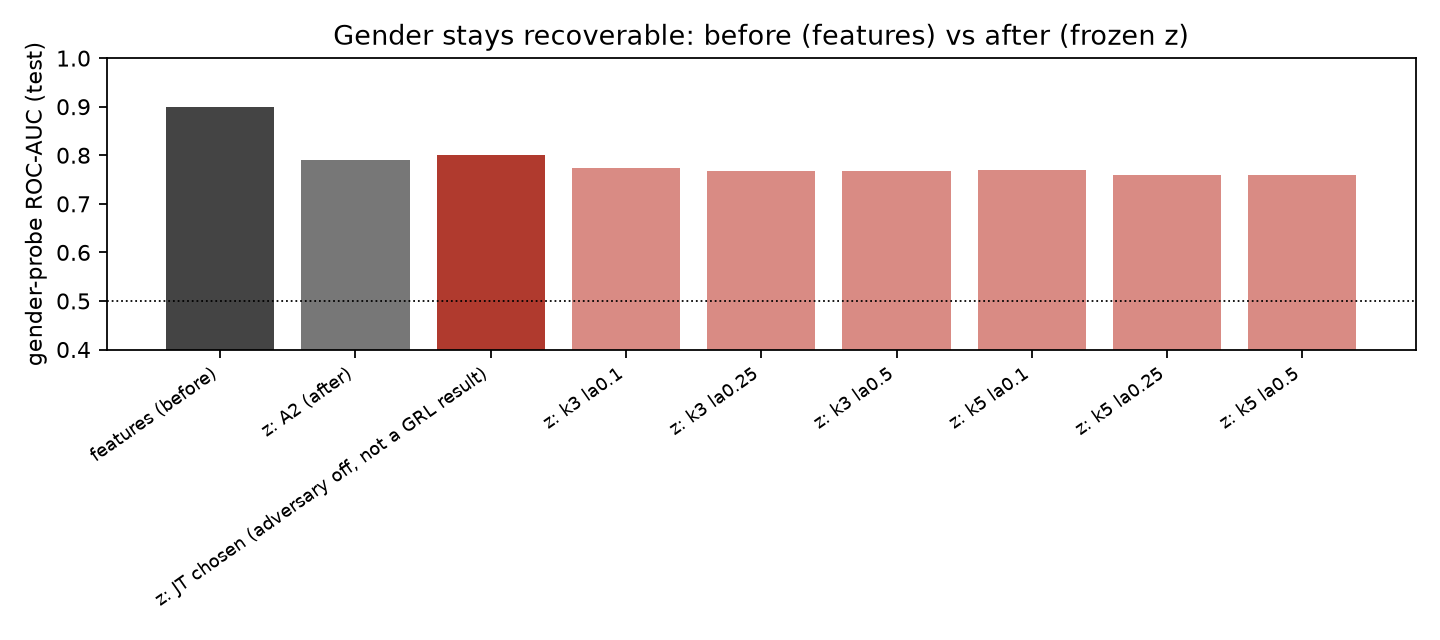

tradeoff_sweep_validation


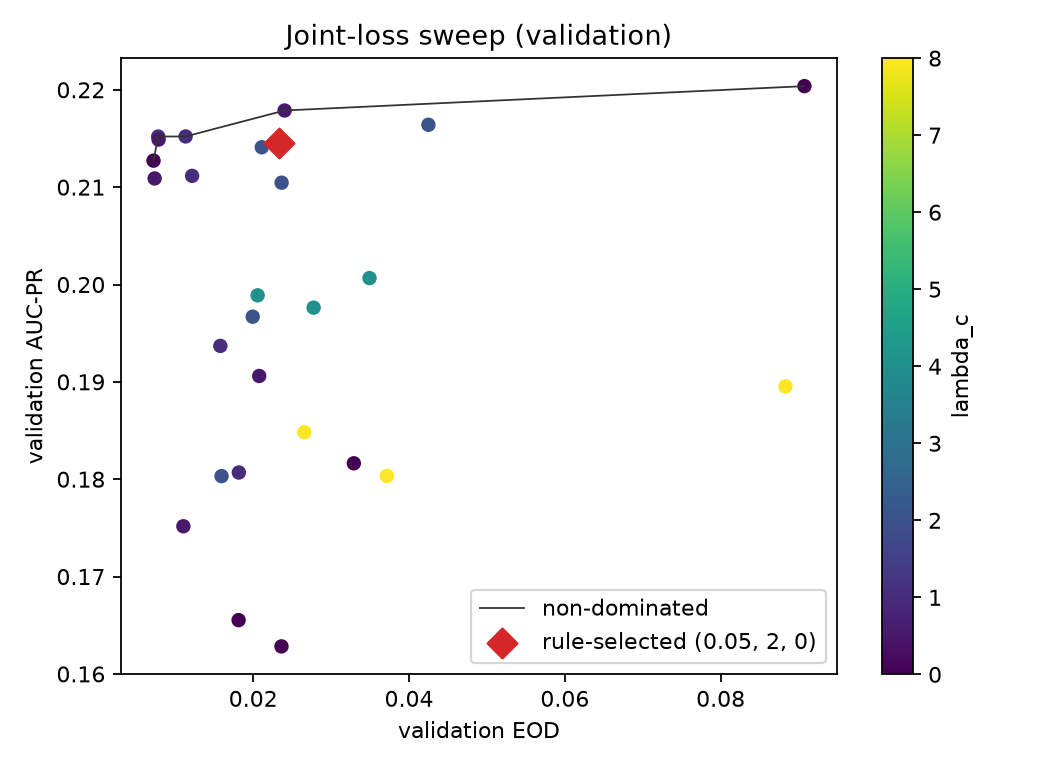

fairness_groups


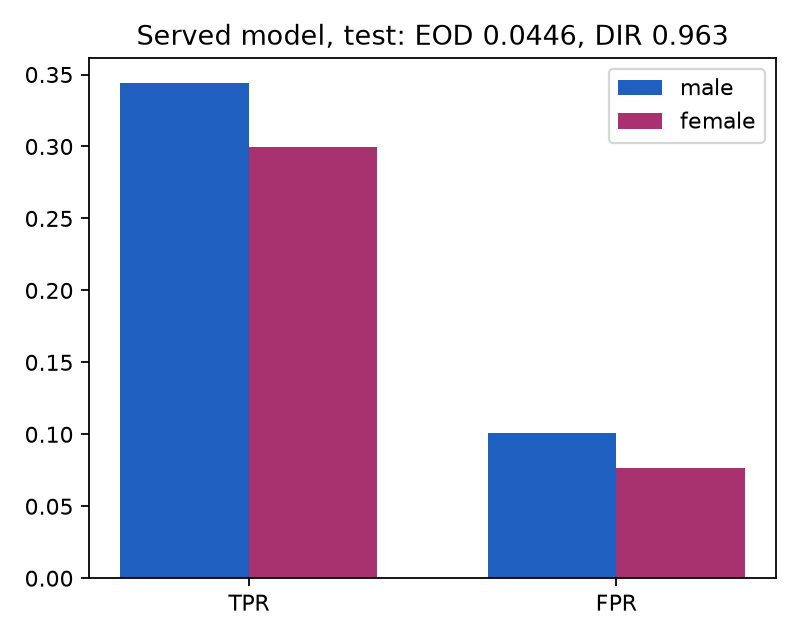

taiwan_pareto


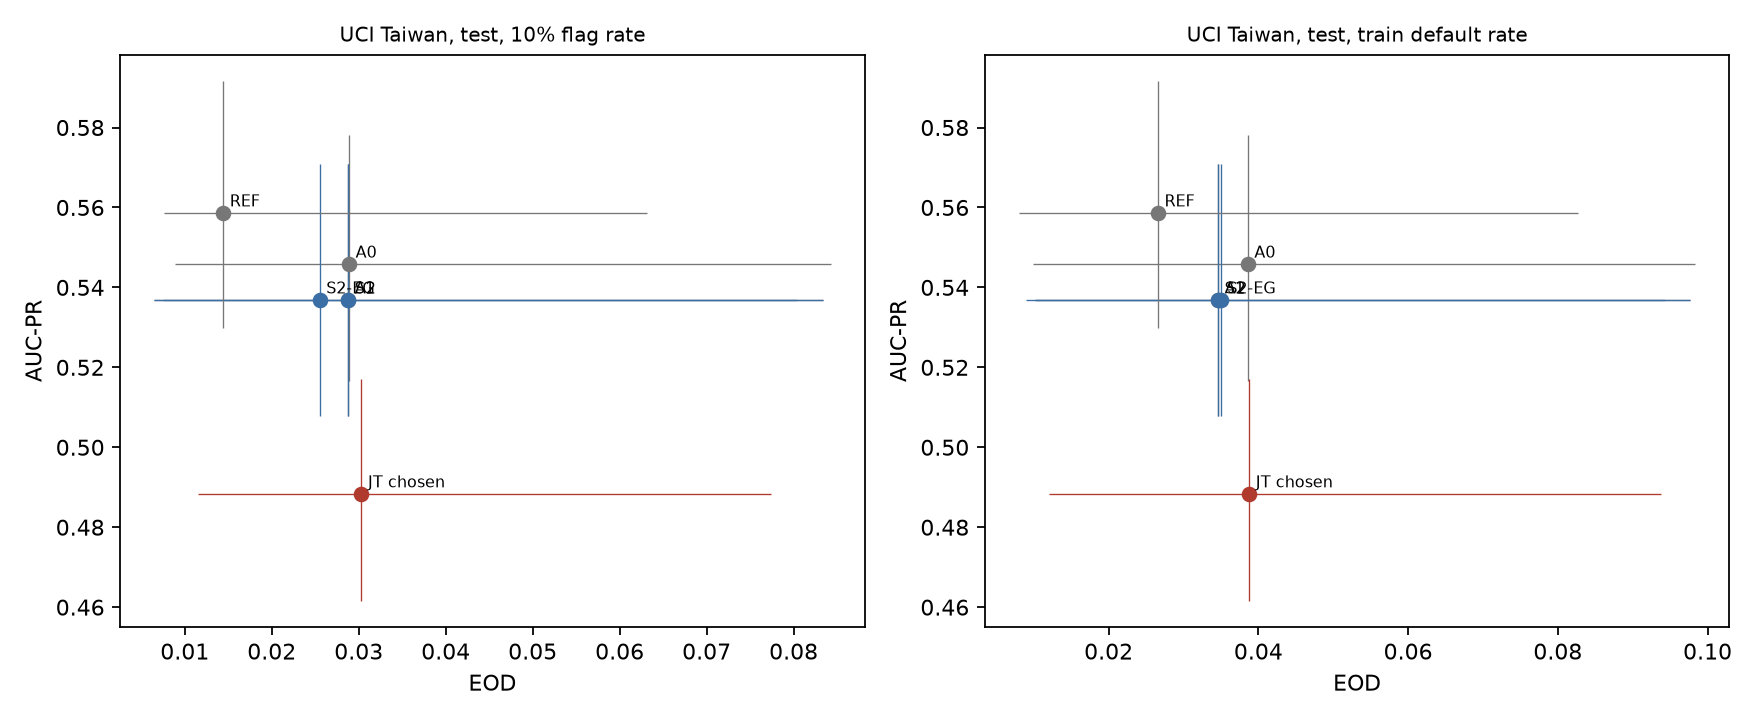

In [2]:
for n in ['pareto_deployable_test', 'reliability_by_gender', 'leakage_before_after', 'tradeoff_sweep_validation', 'fairness_groups', 'taiwan_pareto']:
    print(n); display(Image(filename=str(ROOT / 'artifacts' / 'figures' / (n + '.png')), width=900))

## Tables

In [3]:
T = ROOT / 'artifacts' / 'tables'
for n in ['test_results_all_arms.csv', 'val_vs_test.csv', 'leakage_after.csv', 'matched_pair.csv', 'taiwan_test.md']:
    print(); print(n)
    if n.endswith('.csv'): display(pd.read_csv(T / n).round(4))
    else: display(Markdown((T / n).read_text(encoding='utf-8')))


test_results_all_arms.csv


,arm,deployable,n_seeds,auc_roc,auc_roc_lo,auc_roc_hi,auc_pr,auc_pr_lo,auc_pr_hi,worst_group_ece,worst_group_ece_lo,worst_group_ece_hi,eod,eod_lo,eod_hi,dir,recall,test_flag_rate
0,A0,True,3,0.7439,0.7357,0.7513,0.2189,0.2094,0.2305,0.0151,0.0140,0.0180,0.0668,0.0432,0.0966,0.9459,0.3173,0.1001
1,A1,True,3,0.6853,0.6768,0.6936,0.1670,0.1594,0.1756,0.1568,0.1536,0.1606,0.0962,0.0709,0.1249,0.9349,0.2479,0.0998
2,A1b,True,3,0.6662,0.6578,0.6747,0.1601,0.1527,0.1687,0.2622,0.2581,0.2667,0.0894,0.0650,0.1161,0.9340,0.2408,0.0990
3,A2,True,3,0.7463,0.7381,0.7539,0.2209,0.2113,0.2321,0.3496,0.3467,0.3528,0.0601,0.0368,0.0913,0.9511,0.3201,0.1016
4,A3,True,3,0.7243,0.7163,0.7322,0.2130,0.2029,0.2237,0.3415,0.3388,0.3446,0.0721,0.0514,0.1007,0.9349,0.3059,0.1015
5,A4,True,3,0.7482,0.7403,0.7556,0.2316,0.2212,0.2435,0.3552,0.3522,0.3584,0.0706,0.0461,0.1000,0.9414,0.3274,0.1012
6,A5,True,3,0.7450,0.7368,0.7530,0.2199,0.2098,0.2308,0.3941,0.3933,0.3949,0.0639,0.0398,0.0927,0.9494,0.3167,0.1009
7,G1,True,3,0.7445,0.7362,0.7522,0.2209,0.2113,0.2325,0.1925,0.1904,0.1945,0.0239,0.0171,0.0505,0.9703,0.3195,0.1017
8,GI,False,3,0.7491,0.7409,0.7561,0.2323,0.2218,0.2448,0.3867,0.3837,0.3901,0.1292,0.1020,0.1591,0.9122,0.3240,0.1009
9,H1,True,3,0.7414,0.7333,0.7490,0.2109,0.2018,0.2212,0.0258,0.0255,0.0281,0.0274,0.0080,0.0541,0.9930,0.3031,0.1009



val_vs_test.csv


,arm,deployable,val_auc_roc,test_auc_roc,optimism_auc_roc,val_auc_pr,test_auc_pr,optimism_auc_pr,val_worst_group_ece,test_worst_group_ece,optimism_worst_group_ece,val_eod,test_eod,optimism_eod,val_dir,test_dir,optimism_dir,val_recall,test_recall,optimism_recall
0,A0,True,0.7439,0.7439,0.0001,0.2201,0.2189,0.0012,0.0140,0.0151,0.0011,0.0831,0.0668,-0.0163,0.9397,0.9459,-0.0061,0.3124,0.3173,-0.0049
1,A1,True,0.6856,0.6853,0.0003,0.1653,0.1670,-0.0016,0.1548,0.1568,0.0020,0.1133,0.0962,-0.0170,0.9354,0.9349,0.0005,0.2491,0.2479,0.0012
2,A1b,True,0.6680,0.6662,0.0017,0.1586,0.1601,-0.0014,0.2593,0.2622,0.0029,0.1026,0.0894,-0.0132,0.9364,0.9340,0.0023,0.2437,0.2408,0.0030
3,A2,True,0.7460,0.7463,-0.0002,0.2212,0.2209,0.0003,0.3502,0.3496,-0.0006,0.0763,0.0601,-0.0162,0.9455,0.9511,-0.0056,0.3204,0.3201,0.0004
4,A3,True,0.7152,0.7243,-0.0090,0.1992,0.2130,-0.0138,0.3415,0.3415,-0.0000,0.1051,0.0721,-0.0330,0.9295,0.9349,-0.0055,0.2982,0.3059,-0.0078
5,A4,True,0.7465,0.7482,-0.0017,0.2218,0.2316,-0.0098,0.3551,0.3552,0.0001,0.0962,0.0706,-0.0255,0.9367,0.9414,-0.0046,0.3197,0.3274,-0.0077
6,A5,True,0.7443,0.7450,-0.0007,0.2192,0.2199,-0.0007,0.3929,0.3941,0.0012,0.0890,0.0639,-0.0252,0.9430,0.9494,-0.0063,0.3190,0.3167,0.0023
7,G1,True,0.7439,0.7445,-0.0006,0.2188,0.2209,-0.0021,0.1893,0.1925,0.0032,0.0447,0.0239,-0.0208,0.9663,0.9703,-0.0040,0.3185,0.3195,-0.0010
8,GI,False,0.7488,0.7491,-0.0003,0.2234,0.2323,-0.0089,0.3875,0.3867,-0.0007,0.1647,0.1292,-0.0354,0.9064,0.9122,-0.0058,0.3190,0.3240,-0.0050
9,H1,True,0.7408,0.7414,-0.0006,0.2094,0.2109,-0.0015,0.0261,0.0258,-0.0004,0.0069,0.0274,0.0205,0.9875,0.9930,-0.0055,0.3041,0.3031,0.0010



leakage_after.csv


,arm,n_seeds,probe_lgbm_test_auc,probe_lgbm_test_sd,probe_logistic_test_auc,probe_lgbm_val_auc,shap_probe_test_auc_seed0,shap_method,before_gender_from_X_test_auc,note
0,A2,3,0.7911,0.0194,0.7435,0.7917,0.8010,shap.GradientExplainer,0.9003,NaN
1,JT chosen,3,0.8006,0.0049,0.7541,0.8006,0.8109,shap.GradientExplainer,0.9003,"adversary off, not a GRL result"
2,JT tuned,3,0.8162,0.0127,0.7671,0.8127,0.7848,shap.GradientExplainer,0.9003,"adversary off, not a GRL result"
3,JT-A k3 la0.1,5,0.7731,0.0080,0.6983,0.7698,0.7894,shap.GradientExplainer,0.9003,NaN
4,JT-A k3 la0.25,5,0.7676,0.0160,0.6882,0.7674,0.7972,shap.GradientExplainer,0.9003,NaN
5,JT-A k3 la0.5,5,0.7684,0.0184,0.7078,0.7665,0.7707,shap.GradientExplainer,0.9003,NaN
6,JT-A k5 la0.1,5,0.7703,0.0113,0.6780,0.7691,0.7824,shap.GradientExplainer,0.9003,NaN
7,JT-A k5 la0.25,5,0.7589,0.0122,0.6677,0.7564,0.7798,shap.GradientExplainer,0.9003,NaN
8,JT-A k5 la0.5,5,0.7596,0.0156,0.6907,0.7565,0.7998,shap.GradientExplainer,0.9003,NaN



matched_pair.csv


,arm,mean,median,p95,max
0,A2,0.0297,0.0165,0.1058,0.3279
1,H1,0.0234,0.0156,0.0722,0.2247
2,H2,0.0136,0.0101,0.0384,0.1203
3,H3,0.0036,0.0029,0.0093,0.0226
4,JT-A k3 la0.1,0.0337,0.0225,0.1037,0.2318
5,JT-A k3 la0.25,0.0340,0.0214,0.1094,0.3165
6,JT-A k3 la0.5,0.0375,0.0223,0.1264,0.3086
7,JT-A k5 la0.1,0.0353,0.0216,0.1158,0.2593
8,JT-A k5 la0.25,0.0345,0.0189,0.1236,0.2724
9,JT-A k5 la0.5,0.0354,0.0194,0.1260,0.2941



taiwan_test.md


| arm | use | rate | auc_roc | auc_pr | worst_group_ece | eod | dir | recall |
|---|---|---|---|---|---|---|---|---|
| A0 | deployable | 10% flag rate | 0.7738 | 0.5458 | 0.0292 | 0.0289 | 0.9748 | 0.3216 |
| A0 | deployable | train default rate | 0.7738 | 0.5458 | 0.0292 | 0.0386 | 0.9631 | 0.5327 |
| A2 | deployable | 10% flag rate | 0.7725 | 0.5368 | 0.2262 | 0.0288 | 0.9783 | 0.3162 |
| A2 | deployable | train default rate | 0.7725 | 0.5368 | 0.2262 | 0.0346 | 0.9595 | 0.5256 |
| S1 | deployable | 10% flag rate | 0.7725 | 0.5368 | 0.0298 | 0.0288 | 0.9783 | 0.3162 |
| S1 | deployable | train default rate | 0.7725 | 0.5368 | 0.0298 | 0.0346 | 0.9595 | 0.5256 |
| S2-EG | deployable | 10% flag rate | 0.7725 | 0.5368 | 0.0298 | 0.0255 | 0.9798 | 0.3142 |
| S2-EG | deployable | train default rate | 0.7725 | 0.5368 | 0.0298 | 0.0350 | 0.9609 | 0.5270 |
| S2-GT | analysis only | 10% flag rate | 0.7725 | 0.5368 | 0.0298 | 0.0542 | 0.9886 | 0.3122 |
| S2-GT | analysis only | train default rate | 0.7725 | 0.5368 | 0.0298 | 0.0289 | 0.9834 | 0.5206 |
| JT chosen | deployable | 10% flag rate | 0.7494 | 0.4883 | 0.0294 | 0.0303 | 0.9786 | 0.2767 |
| JT chosen | deployable | train default rate | 0.7494 | 0.4883 | 0.0294 | 0.0388 | 0.9740 | 0.4908 |
| REF | deployable | 10% flag rate | 0.7943 | 0.5586 | 0.0307 | 0.0144 | 0.9770 | 0.3317 |
| REF | deployable | train default rate | 0.7943 | 0.5586 | 0.0307 | 0.0266 | 0.9621 | 0.5588 |
